In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pi_cation_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import pie
from edautils.plot import plot

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3'
}

os.chdir(pi_cation_dir)

# Heteroatom vs Pure Aromatic

# Classification

In [4]:
processed_df = pd.read_csv('pi_cation_EDA_clean.csv', index_col=0)
print(processed_df.shape[0])

1505


In [5]:
components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

include_all = True
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    # for x in ["Heterocyclic", "Carbocyclic"]:
    #     data = processed_df.query(f'group1 == "{x}"')[c]
    #     line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    for x in ["Cation Prot", "Cation Lig"]:
        data = processed_df.query(f'group2 == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

Total$-41.13\ (-38.67)$ & $-42.02\ (-38.76)$ & $-38.78\ (-38.64)$ \\
Pauli$20.25\ (16.70)$ & $19.22\ (15.37)$ & $22.94\ (20.82)$ \\
Electrostatics$-21.90\ (-19.63)$ & $-20.87\ (-17.32)$ & $-24.58\ (-24.50)$ \\
Dispersion$-19.14\ (-18.77)$ & $-18.81\ (-18.01)$ & $-20.02\ (-19.35)$ \\
Polarization$-16.70\ (-14.47)$ & $-18.11\ (-15.56)$ & $-13.01\ (-12.96)$ \\
Charge Transfer$-3.64\ (-2.96)$ & $-3.46\ (-2.68)$ & $-4.12\ (-3.80)$ \\


# Violin + Bar Plot

## Cation on Protein vs Ligand

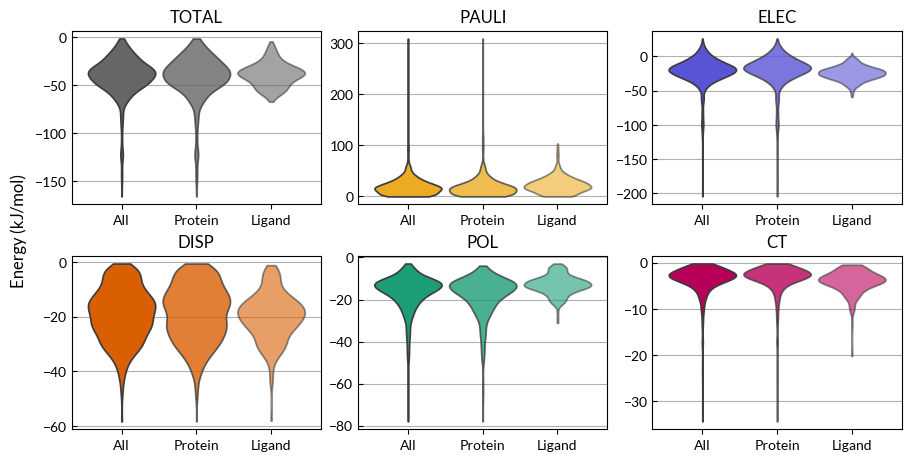

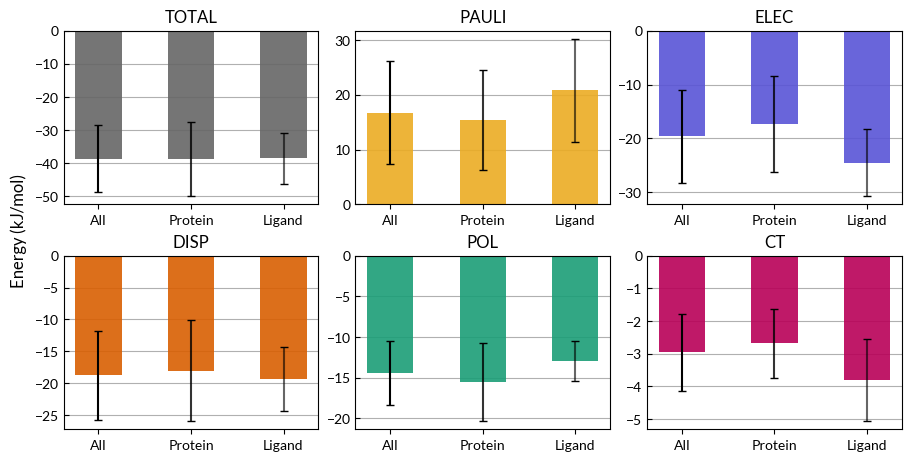

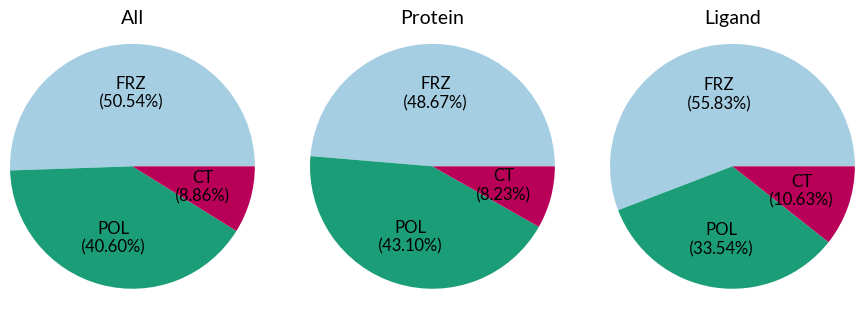

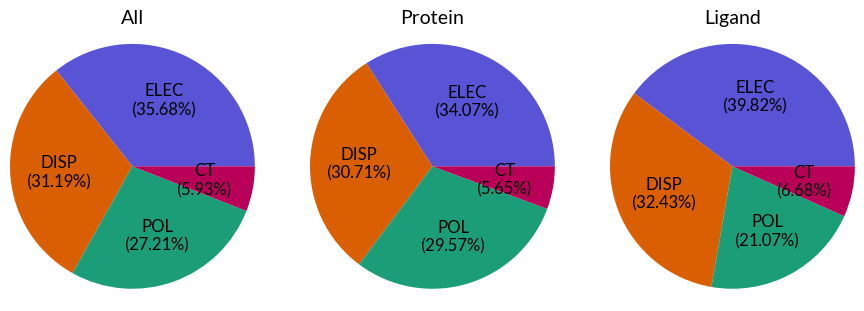

In [8]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'group2'
groups = ['ALL', 'Cation Prot', 'Cation Lig']
labels = ['All', 'Protein', 'Ligand']

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_cation.pdf')

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_cation.pdf')


fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df, type='TOTAL')
fig.savefig('Visualizations/pie_frz_pol_ct_cation.pdf')


fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df, type='STABILIZING')
fig.savefig('Visualizations/pie_stabilizing_cation.pdf')

## Heterocyclic vs Carbocyclic Rings

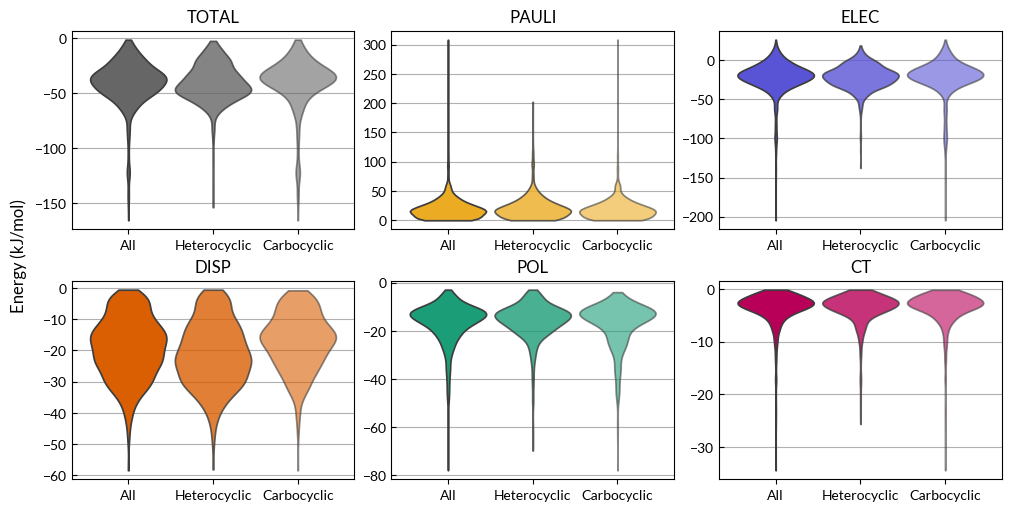

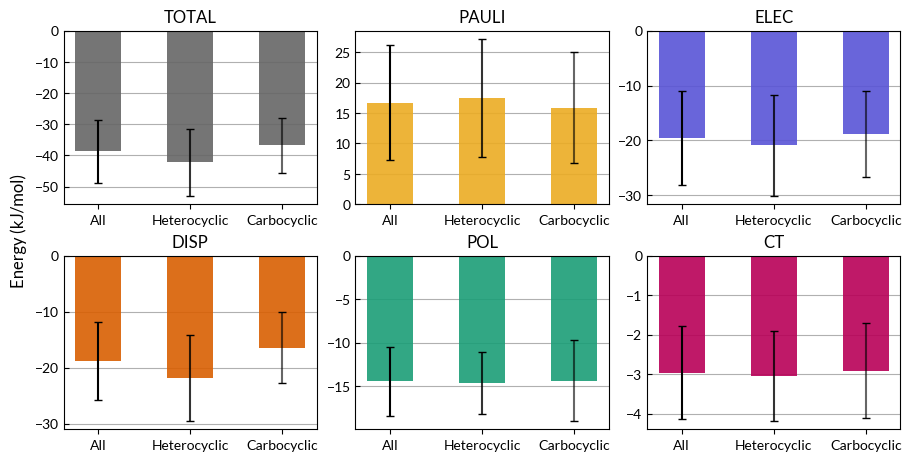

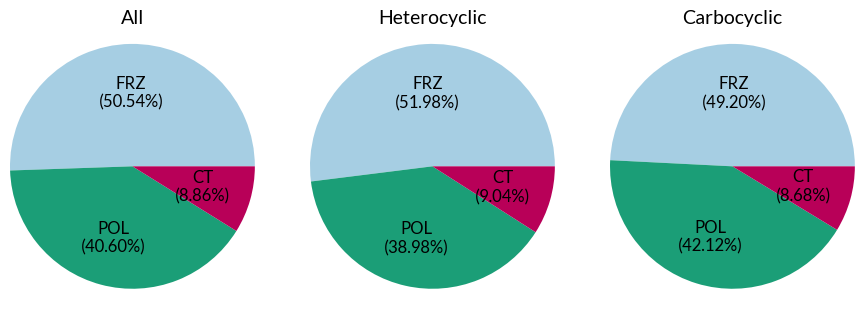

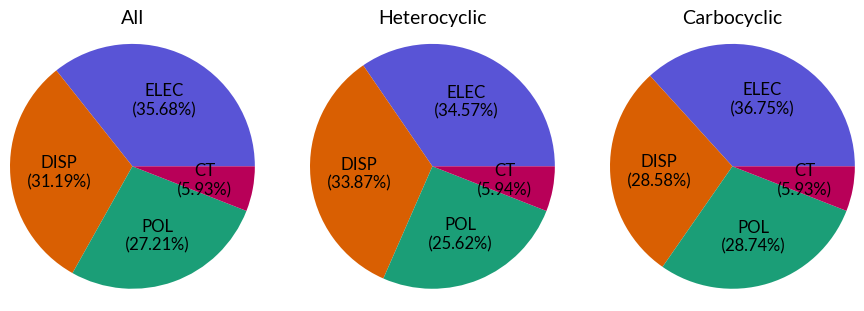

In [9]:
group_name = 'group1'
groups = ['ALL', 'Heterocyclic', 'Carbocyclic']
labels = ['All', 'Heterocyclic', 'Carbocyclic']

fig, axes = plt.subplots(2, 3, figsize=(10, 5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_ring.pdf')

fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_ring.pdf')

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_frz_pol_ct_ring.pdf')

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df, type='STABILIZING')
fig.savefig('Visualizations/pie_stabilizing_ring.pdf')

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/289752812.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/289752812.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/289752812.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


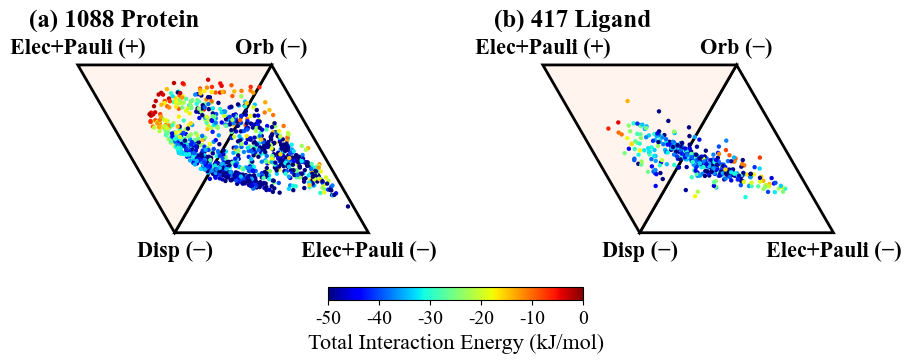

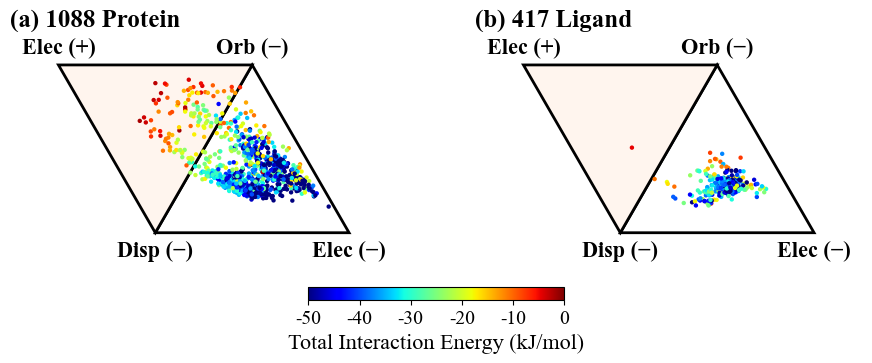

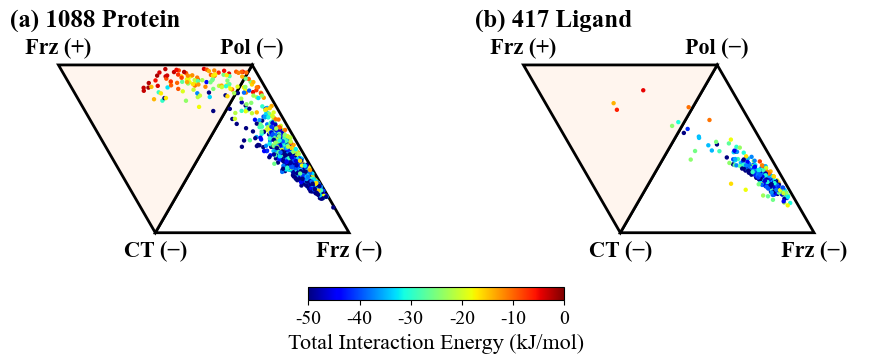

In [10]:
cmap_range = [-50, 0]
types = ['frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct']

group_name = 'group2'
groups = ['ALL', 'Cation Prot', 'Cation Lig']
labels = ['All', 'Protein', 'Ligand']

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[0]), processed_df.query(f"{group_name} == '{groups[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[0]), processed_df.query(f"{group_name} == '{groups[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_elec+pauli_orb_disp_cation.pdf")



fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[1]), processed_df.query(f"{group_name} == '{groups[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[1]), processed_df.query(f"{group_name} == '{groups[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_elec_orb_disp_cation.pdf")



fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[2]), processed_df.query(f"{group_name} == '{groups[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[2]), processed_df.query(f"{group_name} == '{groups[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_frz_pol_ct_cation.pdf")


/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/3057155214.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/3057155214.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/3057155214.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


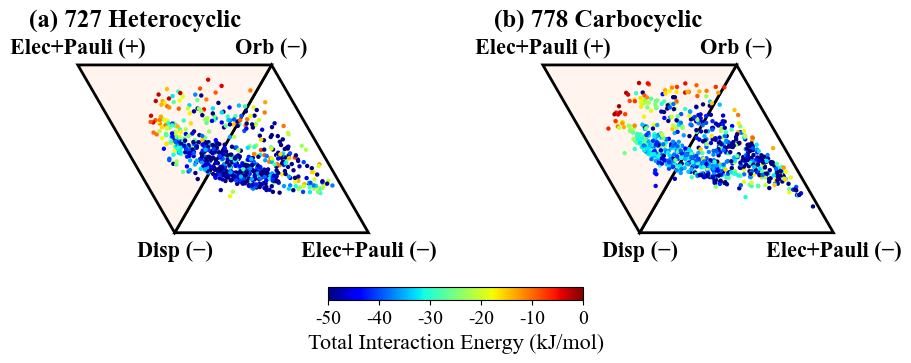

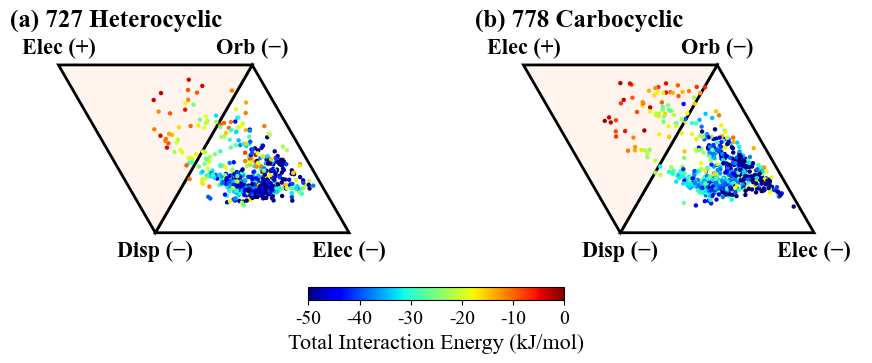

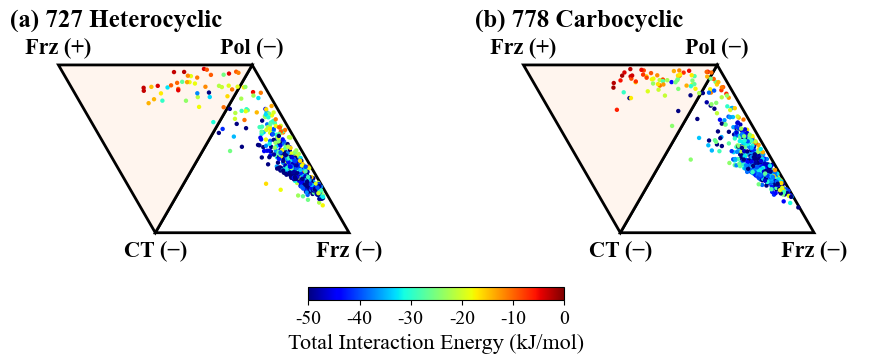

In [11]:
cmap_range = [-50, 0]
types = ['frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct']

group_name = 'group1'
groups = ['ALL', 'Heterocyclic', 'Carbocyclic']
labels = ['All', 'Heterocyclic', 'Carbocyclic']

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[0]), processed_df.query(f"{group_name} == '{labels[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[0]), processed_df.query(f"{group_name} == '{labels[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_elec+pauli_orb_disp_ring.pdf")



fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[1]), processed_df.query(f"{group_name} == '{labels[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[1]), processed_df.query(f"{group_name} == '{labels[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_elec_orb_disp_ring.pdf")



fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sc = plot('ternary', (labels[1], 'a', types[2]), processed_df.query(f"{group_name} == '{labels[1]}'"), axes[0], cmap_range)
plot('ternary', (labels[2], 'b', types[2]), processed_df.query(f"{group_name} == '{labels[2]}'"), axes[1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
plt.savefig("Visualizations/ternary_frz_pol_ct_ring.pdf")


# Aromatic Residues (Tyrosine H-Bonding?)

# Total pairs: 147
# Total pairs: 61
# Total pairs: 171
# Total pairs: 38
Total & $-35.29\ (-36.25)$ & $-34.44\ (-34.78)$ & $-46.94\ (-48.74)$ & $-22.52\ (-19.68)$ \\
Pauli & $20.82\ (19.62)$ & $24.51\ (20.90)$ & $25.74\ (23.85)$ & $16.06\ (8.65)$ \\
Electrostatics & $-21.57\ (-21.99)$ & $-22.91\ (-21.89)$ & $-30.20\ (-30.62)$ & $-13.63\ (-9.80)$ \\
Dispersion & $-18.67\ (-18.96)$ & $-19.72\ (-19.03)$ & $-22.90\ (-22.26)$ & $-12.70\ (-12.72)$ \\
Polarization & $-12.17\ (-12.30)$ & $-12.18\ (-11.81)$ & $-14.91\ (-14.55)$ & $-9.00\ (-7.03)$ \\
Charge Transfer & $-3.70\ (-3.59)$ & $-4.14\ (-3.93)$ & $-4.67\ (-4.17)$ & $-3.25\ (-1.73)$ \\


/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_39286/1807249957.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


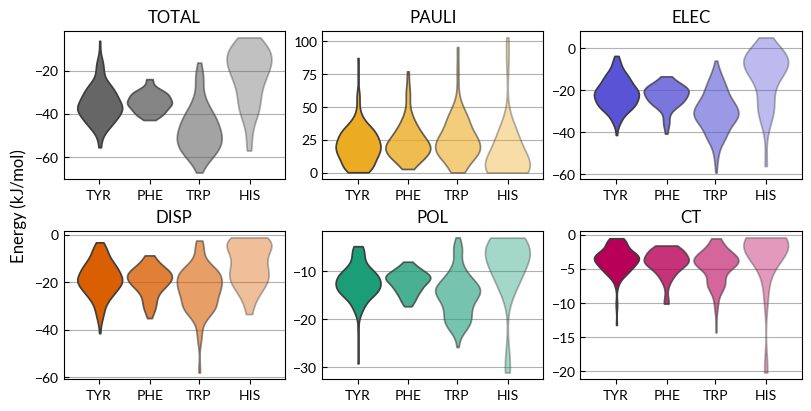

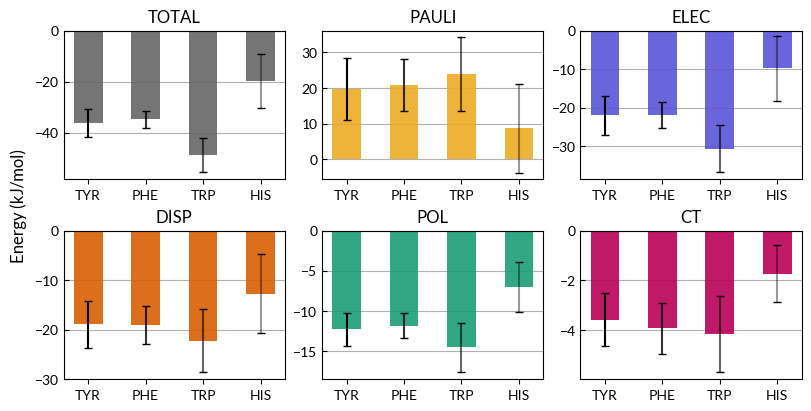

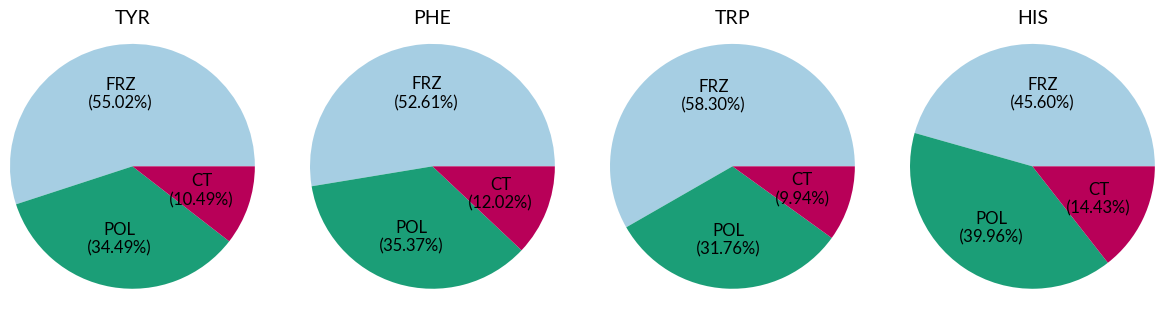

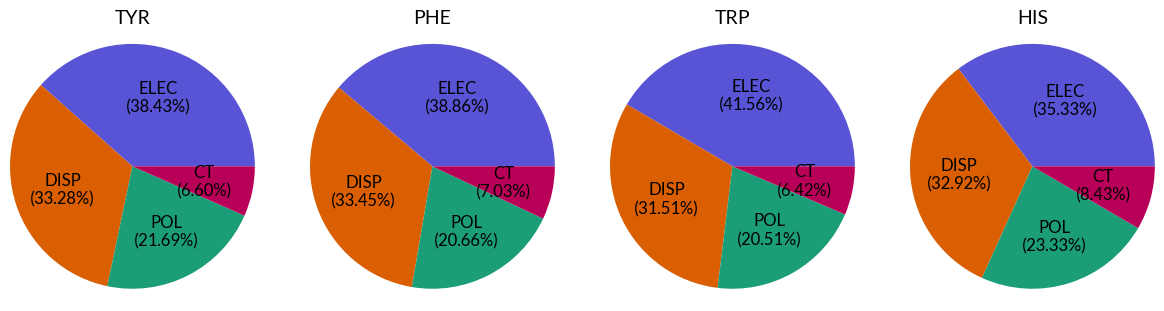

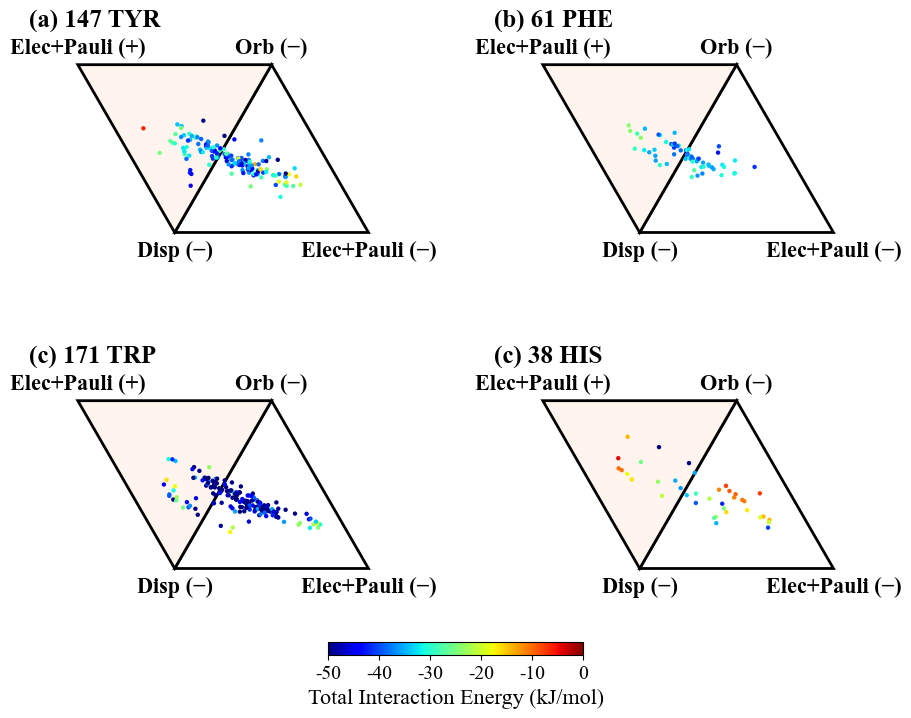

In [12]:
group_name = 'restype'
groups = ['TYR', 'PHE', 'TRP', 'HIS']
labels = ['TYR', 'PHE', 'TRP', 'HIS']

for group in groups:
    print('# Total pairs:', len(processed_df.query(f"restype in '{group}'")))

include_all = False
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in groups:
        data = processed_df.query(f'restype == "{x}"')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")

fig, axes = plt.subplots(1, 4, constrained_layout=True, figsize=(12, 3))
pie(axes, group_name, groups, labels, processed_df, isFloat=False)

fig, axes = plt.subplots(1, 4, constrained_layout=True, figsize=(12, 3))
pie(axes, group_name, groups, labels, processed_df, type='STABILIZING', isFloat=False)

cmap_range = [-50, 0]
types = ['frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct']

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
sc = plot('ternary', (labels[0], 'a', types[0]), processed_df.query(f"{group_name} == '{groups[0]}'"), axes[0, 0], cmap_range)
plot('ternary', (labels[1], 'b', types[0]), processed_df.query(f"{group_name} == '{groups[1]}'"), axes[0, 1], cmap_range)
plot('ternary', (labels[2], 'c', types[0]), processed_df.query(f"{group_name} == '{groups[2]}'"), axes[1, 0], cmap_range)
plot('ternary', (labels[3], 'c', types[0]), processed_df.query(f"{group_name} == '{groups[3]}'"), axes[1, 1], cmap_range)
cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

# Aromatic Ligand Clustering?